# Regression & Predictive Analytics: Skytrax Airline Reviews (Group 7)

This notebook trains the regression models from our slide deck on the full **Skytrax Airline Review Data** file (64,740 reviews), step by step, with the mathematics shown alongside the code. Every number on the slides is calculated here.

**Problem definition.** Each review gives an overall rating (1 to 10) and several 1–5 star service scores. Airlines cannot tell from the raw scores which service matters most.

* **Objective:** predict the overall rating from five service scores using linear regression.
* **Research question:** which services move the overall rating most, and how accurately can we predict it?

**How to run.** Put this notebook in the same folder as `Skytrax_Airline_Review_Data.xlsx`, then run the cells from top to bottom (Run → Run All Cells).

In [30]:
# If a package is missing, uncomment and run this line once:
# %pip install pandas numpy matplotlib scikit-learn scipy openpyxl statsmodels joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.width", 140)
DATA = "Skytrax_Airline_Review_Data.xlsx"   # change this path if the file is elsewhere

## 1. Load and explore the dataset

In [31]:
df = pd.read_excel(DATA)
print("Rows, columns:", df.shape)
df.head(3)

Rows, columns: (64740, 19)


,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
0,2025-08-04,1.0,"""showed zero empathy for passengers""",Trip Verified,My afternoon flight was delayed and eventuall...,NaN,business,economy_class,dubai_to_kochi,august_2025,1.0,2.0,2.0,2.0,1.0,1.0,1.0,no,spicejet
1,2025-07-21,2.0,"""Extremely dissatisfied""",Trip Verified,The flight was postponed 3 times with insuffi...,NaN,family_leisure,economy_class,pune_to_dubai,july_2025,1.0,3.0,NaN,NaN,3.0,NaN,2.0,no,spicejet
2,2025-04-19,2.0,"""Very bad experience""",Trip Verified,They will charge you for your hand baggage if...,NaN,business,economy_class,mumbai_to_kolkata,april_2025,3.0,3.0,3.0,NaN,1.0,NaN,2.0,no,spicejet


In [32]:
# How many values are missing in each column?
df.isna().sum().to_frame("missing").assign(percent=lambda t: (100 * t.missing / len(df)).round(1))

,missing,percent
review_date,0,0.0
over_all_rating,116,0.2
review_header,0,0.0
trip_verified,11693,18.1
review_text,147,0.2
aircraft,36767,56.8
type_of_traveller,2638,4.1
seat_type,38,0.1
route,2861,4.4
date_flown,2736,4.2


In [33]:
print("Airlines:", df.airline_name.nunique())
df.airline_name.value_counts().head(10)

Airlines: 109


airline_name
american-airlines          5900
united-airlines            4520
british-airways            3470
delta-air-lines            2860
turkish-airlines           2440
qatar-airways              2300
lufthansa                  2130
air-canada                 2130
emirates                   1980
china-southern-airlines    1730
Name: count, dtype: int64

## 2. Clean the data

Regression needs every X value, so we keep only reviews that have the overall rating **and** all five service scores we use. Wifi and in-flight entertainment are left out because most reviews skip them.

In [34]:
Y_COL  = "over_all_rating"
X_COLS = ["value_for_money", "ground_service", "seat_comfort", "cabin_staff_service", "food__beverages"]
NAMES  = {"value_for_money": "Value", "ground_service": "Ground", "seat_comfort": "Seat",
          "cabin_staff_service": "Staff", "food__beverages": "Food"}

complete = df.dropna(subset=X_COLS + [Y_COL])
data = complete.drop_duplicates(subset=["review_text", "airline_name", Y_COL]).reset_index(drop=True)

print(f"All reviews:                 {len(df):,}")
print(f"With all six scores:         {len(complete):,}  (dropped {len(df) - len(complete):,})")
print(f"After removing duplicates:   {len(data):,}  (dropped {len(complete) - len(data):,})")

All reviews:                 64,740
With all six scores:         49,459  (dropped 15,281)
After removing duplicates:   49,419  (dropped 40)


                 reviews  percent
over_all_rating                  
Negative (1–3)     23735     48.0
Positive (7–10)    19434     39.3
Mixed (4–6)         6250     12.6

Share of reviews rated exactly 1: 30.0%


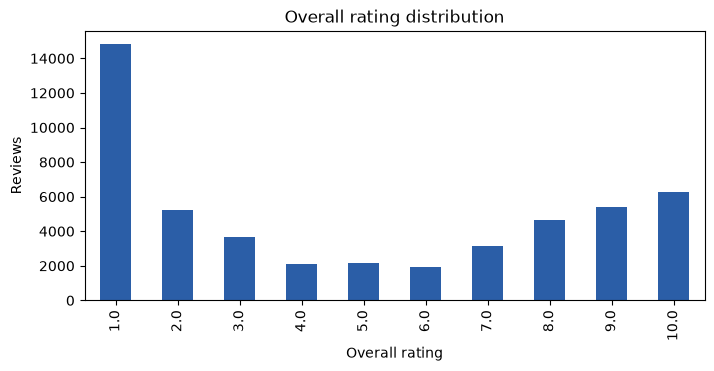

In [35]:
y_all = data[Y_COL]
bands = pd.cut(y_all, [0, 3, 6, 10], labels=["Negative (1–3)", "Mixed (4–6)", "Positive (7–10)"])
print(bands.value_counts().to_frame("reviews").assign(percent=lambda t: (100 * t.reviews / len(data)).round(1)))
print(f"\nShare of reviews rated exactly 1: {(y_all == 1).mean():.1%}")

y_all.value_counts().sort_index().plot(kind="bar", color="#2B5EA7", figsize=(8, 3.5))
plt.title("Overall rating distribution"); plt.xlabel("Overall rating"); plt.ylabel("Reviews"); plt.show()

## 3. Variables and correlation

**Y (dependent):** overall rating, 1 to 10. **X (independent):** five star scores, 1 to 5.

Pearson correlation:

$$ r = \frac{\sum (x-\bar x)(y-\bar y)}{\sqrt{\sum (x-\bar x)^2 \; \sum (y-\bar y)^2}} $$

In [36]:
def pearson_r(x, y):
    dx, dy = x - x.mean(), y - y.mean()
    return (dx * dy).sum() / np.sqrt((dx**2).sum() * (dy**2).sum())

corr_table = pd.DataFrame({
    "X": [NAMES[c] for c in X_COLS],
    "mean stars": [data[c].mean().round(2) for c in X_COLS],
    "r with Y (by hand)": [round(pearson_r(data[c], y_all), 3) for c in X_COLS],
    "r with Y (pandas)": [round(data[c].corr(y_all), 3) for c in X_COLS],
})
corr_table

,X,mean stars,r with Y (by hand),r with Y (pandas)
0,Value,2.81,0.900,0.900
1,Ground,2.78,0.829,0.829
2,Seat,2.96,0.781,0.781
3,Staff,3.20,0.780,0.780
4,Food,2.78,0.781,0.781


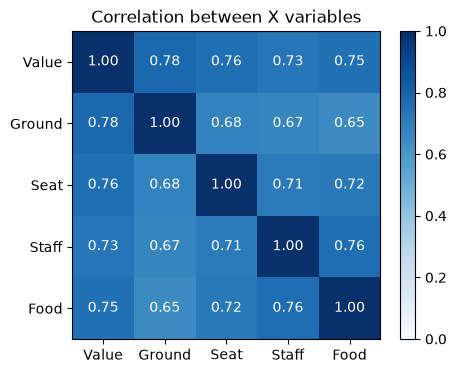

In [37]:
# Correlation between the X variables themselves (used later for multicollinearity)
C = data[X_COLS].rename(columns=NAMES).corr()
plt.figure(figsize=(5, 4))
plt.imshow(C, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(5), C.columns); plt.yticks(range(5), C.columns)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", color="white" if C.iloc[i, j] > 0.6 else "black")
plt.title("Correlation between X variables"); plt.colorbar(); plt.show()

## 4. Train / test split (80% / 20%)

The model **learns** from 80% of reviews and is **tested** on the 20% it has never seen. A fixed random seed (42) makes the split reproducible, so you get the same numbers as the slides.

In [38]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(data))
n_train = int(0.8 * len(data))
train, test = data.iloc[idx[:n_train]], data.iloc[idx[n_train:]]

X_train, y_train = train[X_COLS], train[Y_COL].values
X_test,  y_test  = test[X_COLS],  test[Y_COL].values
print(f"Training reviews: {len(train):,}   Test reviews: {len(test):,}")

Training reviews: 39,535   Test reviews: 9,884


## 5. Evaluation metrics (written by hand)

$$ \text{MAE}=\frac{1}{n}\sum|y-\hat y| \qquad \text{MSE}=\frac{1}{n}\sum(y-\hat y)^2 \qquad \text{RMSE}=\sqrt{\text{MSE}} \qquad R^2 = 1-\frac{SS_{res}}{SS_{tot}} = 1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2} $$

In [39]:
def metrics(y, y_hat):
    e = y - y_hat
    ss_res = (e**2).sum()
    ss_tot = ((y - y.mean())**2).sum()
    return {"MAE": np.abs(e).mean(), "MSE": (e**2).mean(), "RMSE": np.sqrt((e**2).mean()), "R2": 1 - ss_res / ss_tot}

# Baseline: always predict the training average
y_bar = y_train.mean()
baseline = metrics(y_test, np.full(len(y_test), y_bar))
print(f"Training average rating: {y_bar:.2f}")
pd.Series(baseline).round(3)

Training average rating: 4.80


MAE      3.239
MSE     12.214
RMSE     3.495
R2      -0.000
dtype: float64

## 6. Simple linear regression: one X (value for money)

$$ \hat y = b_0 + b_1 x \qquad b_1 = \frac{S_{xy}}{S_{xx}} = \frac{\sum (x-\bar x)(y-\bar y)}{\sum (x-\bar x)^2} \qquad b_0 = \bar y - b_1 \bar x $$

These formulas come from setting the derivatives of $SSE=\sum (y-b_0-b_1x)^2$ to zero (least squares).

In [40]:
x = train["value_for_money"].values
y = y_train

Sxy = ((x - x.mean()) * (y - y.mean())).sum()
Sxx = ((x - x.mean())**2).sum()
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()
print(f"By hand:  Sxy = {Sxy:,.1f}   Sxx = {Sxx:,.1f}")
print(f"          b1 = {b1:.4f}   b0 = {b0:.4f}")

simple = LinearRegression().fit(train[["value_for_money"]], y_train)
print(f"sklearn:  b1 = {simple.coef_[0]:.4f}   b0 = {simple.intercept_:.4f}")
print(f"\nFitted line:  Rating = {b0:.3f} + {b1:.3f} × Value")

By hand:  Sxy = 198,073.5   Sxx = 101,217.1
          b1 = 1.9569   b0 = -0.6991
sklearn:  b1 = 1.9569   b0 = -0.6991

Fitted line:  Rating = -0.699 + 1.957 × Value


In [41]:
# Plug in each value score (slide: intercept and slope)
pd.DataFrame({"Value score": range(1, 6), "Predicted rating": [round(b0 + b1 * v, 2) for v in range(1, 6)]}).set_index("Value score").T

Value score,1,2,3,4,5
Predicted rating,1.26,3.21,5.17,7.13,9.09


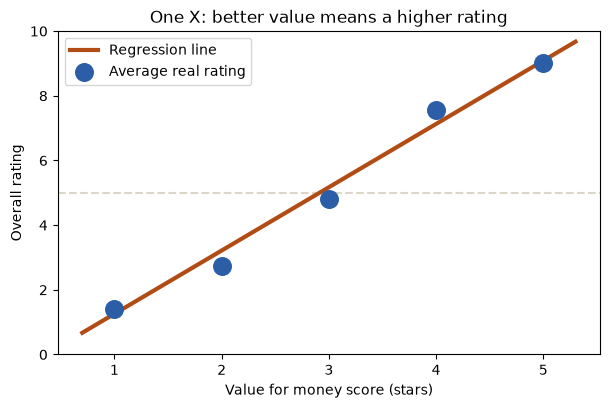

value_for_money
1.0    1.41
2.0    2.73
3.0    4.80
4.0    7.56
5.0    9.02
Name: over_all_rating, dtype: float64


In [42]:
means = data.groupby("value_for_money")[Y_COL].mean()
xs = np.array([0.7, 5.3])
plt.figure(figsize=(7, 4.2))
plt.axhline(5, color="#DDD6C8", ls="--")
plt.plot(xs, b0 + b1 * xs, color="#B14D14", lw=3, label="Regression line")
plt.scatter(means.index, means.values, s=160, color="#2B5EA7", zorder=3, label="Average real rating")
plt.ylim(0, 10); plt.xlabel("Value for money score (stars)"); plt.ylabel("Overall rating")
plt.title("One X: better value means a higher rating"); plt.legend(); plt.show()
print(means.round(2))

In [43]:
simple_test = metrics(y_test, simple.predict(test[["value_for_money"]]))
r = pearson_r(data["value_for_money"], y_all)
print(f"Test R² of simple model: {simple_test['R2']:.3f}")
print(f"r² of value for money:   {r**2:.3f}   (in simple regression, R² = r²)")

Test R² of simple model: 0.809
r² of value for money:   0.811   (in simple regression, R² = r²)


## 7. Multiple linear regression: five Xs

$$ \hat y = b_0 + b_1X_1 + b_2X_2 + b_3X_3 + b_4X_4 + b_5X_5 \qquad \text{in matrix form: } \; \mathbf b = (X^\top X)^{-1} X^\top \mathbf y $$

$X$ has a column of 1s (for the intercept) plus the five scores.

In [44]:
X = np.column_stack([np.ones(len(train)), X_train.values])     # 39,535 × 6
XtX = X.T @ X
Xty = X.T @ y_train
b = np.linalg.solve(XtX, Xty)                                   # solves (XᵀX) b = Xᵀy

multi = LinearRegression().fit(X_train, y_train)

coef = pd.DataFrame({"by hand (XᵀX)⁻¹Xᵀy": b,
                     "sklearn": np.r_[multi.intercept_, multi.coef_]},
                    index=["Intercept"] + [NAMES[c] for c in X_COLS]).round(4)
print("XᵀX =\n", XtX.round(0))
coef

XᵀX =
 [[ 39535. 111047. 109746. 116785. 126235. 109819.]
 [111047. 413129. 388268. 397674. 427963. 379976.]
 [109746. 388268. 408120. 387435. 418078. 367574.]
 [116785. 397674. 387435. 428871. 437434. 386738.]
 [126235. 427963. 418078. 437434. 501685. 422576.]
 [109819. 379976. 367574. 386738. 422576. 395747.]]


,by hand (XᵀX)⁻¹Xᵀy,sklearn
Intercept,-1.7507,-1.7507
Value,0.9961,0.9961
Ground,0.5354,0.5354
Seat,0.2371,0.2371
Staff,0.2674,0.2674
Food,0.2555,0.2555


In [45]:
terms = " + ".join(f"{b[i+1]:.3f}·{NAMES[c]}" for i, c in enumerate(X_COLS))
print(f"Rating = {b[0]:.3f} + {terms}")

Rating = -1.751 + 0.996·Value + 0.535·Ground + 0.237·Seat + 0.267·Staff + 0.255·Food


### Standard errors and t-statistics (are the slopes significant?)

$$ \hat\sigma^2 = \frac{SSE}{n-p-1} \qquad \text{Var}(\mathbf b) = \hat\sigma^2 (X^\top X)^{-1} \qquad t = \frac{b_j}{SE(b_j)} $$

In [46]:
resid_train = y_train - X @ b
n, p = X.shape[0], X.shape[1] - 1
sigma2 = (resid_train**2).sum() / (n - p - 1)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(XtX)))
t = b / se
p_values = 2 * stats.t.sf(np.abs(t), df=n - p - 1)
pd.DataFrame({"coef": b, "std error": se, "t": t, "p-value": p_values},
             index=["Intercept"] + [NAMES[c] for c in X_COLS]).round(4)

,coef,std error,t,p-value
Intercept,-1.7507,0.0148,-118.5605,0.0
Value,0.9961,0.0076,131.2654,0.0
Ground,0.5354,0.0063,85.2691,0.0
Seat,0.2371,0.0071,33.5846,0.0
Staff,0.2674,0.0067,40.0191,0.0
Food,0.2555,0.0070,36.3495,0.0


In [47]:
# Optional cross-check with statsmodels (gives the same numbers in a full summary table)
try:
    import statsmodels.api as sm
    print(sm.OLS(y_train, sm.add_constant(X_train.rename(columns=NAMES))).fit().summary())
except ImportError:
    print("statsmodels not installed: run  %pip install statsmodels  to see the full summary.")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.878
Method:                 Least Squares   F-statistic:                 5.708e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:24:07   Log-Likelihood:                -63716.
No. Observations:               39535   AIC:                         1.274e+05
Df Residuals:                   39529   BIC:                         1.275e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.7507      0.015   -118.561      0.0

## 8. Interpretation: why did the Value slope halve?

In the simple model, value for money was also carrying the effect of the other services, because the scores are correlated (0.73–0.78). This is **omitted-variable bias**. Once each service has its own coefficient, Value keeps only its own effect.

In [48]:
print(f"Value slope, simple model:   {b1:.3f}")
print(f"Value slope, multiple model: {b[1]:.3f}")
print("\nCorrelation of value for money with the other scores:")
print(data[X_COLS].corr()["value_for_money"].drop("value_for_money").rename(NAMES).round(2))

Value slope, simple model:   1.957
Value slope, multiple model: 0.996

Correlation of value for money with the other scores:
Ground    0.78
Seat      0.76
Staff     0.73
Food      0.75
Name: value_for_money, dtype: float64


## 9. Predicting two new reviews

In [49]:
def predict_rating(value, ground, seat, staff, food):
    """Predicted overall rating from five 1–5 star scores."""
    return b[0] + b[1]*value + b[2]*ground + b[3]*seat + b[4]*staff + b[5]*food

review_a = predict_rating(value=4, ground=4, seat=4, staff=5, food=4)
review_b = predict_rating(value=1, ground=1, seat=1, staff=1, food=1)
print(f"Review A (4, 4, 4, 5, 4): {review_a:.2f}")
print(f"Review B (all 1 star):    {review_b:.2f}   ← below the minimum rating of 1")

Review A (4, 4, 4, 5, 4): 7.68
Review B (all 1 star):    0.54   ← below the minimum rating of 1


## 10. Results on the test set

In [50]:
y_hat = multi.predict(X_test)
multi_test = metrics(y_test, y_hat)

results = pd.DataFrame([baseline, simple_test, multi_test],
                       index=[f"Baseline: always guess {y_bar:.2f}", "Simple: Value only", "Multiple: five Xs"]).round(3)
results

,MAE,MSE,RMSE,R2
Baseline: always guess 4.80,3.239,12.214,3.495,-0.000
Simple: Value only,1.067,2.333,1.527,0.809
Multiple: five Xs,0.885,1.495,1.223,0.878


In [51]:
# Same numbers with sklearn's own functions
print("sklearn  MAE ", round(mean_absolute_error(y_test, y_hat), 3),
      "  MSE ", round(mean_squared_error(y_test, y_hat), 3),
      "  RMSE", round(np.sqrt(mean_squared_error(y_test, y_hat)), 3),
      "  R²  ", round(r2_score(y_test, y_hat), 4))

print(f"\nMAE cut vs baseline:      {(baseline['MAE'] - multi_test['MAE']) / baseline['MAE']:.0%}")
print(f"MSE cut vs simple model:  {(simple_test['MSE'] - multi_test['MSE']) / simple_test['MSE']:.0%}")
print(f"Training R² {r2_score(y_train, multi.predict(X_train)):.4f} vs test R² {multi_test['R2']:.4f}  → no overfitting")
e = y_test - y_hat
print(f"Predictions within 1 point: {(np.abs(e) <= 1).mean():.0%}   within 2 points: {(np.abs(e) <= 2).mean():.0%}")

sklearn  MAE  0.885   MSE  1.495   RMSE 1.223   R²   0.8776

MAE cut vs baseline:      73%
MSE cut vs simple model:  36%
Training R² 0.8784 vs test R² 0.8776  → no overfitting
Predictions within 1 point: 68%   within 2 points: 90%


## 11. Checking the five regression assumptions

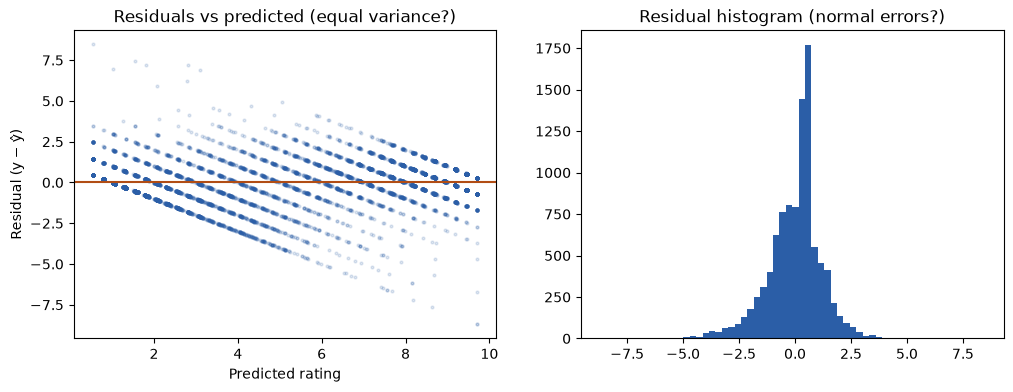

Residual spread (std) by fifth of predicted rating: [0.56, 1.07, 1.73, 1.29, 0.82]
Residual mean -0.011   skew -0.65   excess kurtosis 3.65


In [52]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_hat, e, s=4, alpha=0.15, color="#2B5EA7")
ax[0].axhline(0, color="#B14D14"); ax[0].set_xlabel("Predicted rating"); ax[0].set_ylabel("Residual (y − ŷ)")
ax[0].set_title("Residuals vs predicted (equal variance?)")
ax[1].hist(e, bins=60, color="#2B5EA7"); ax[1].set_title("Residual histogram (normal errors?)")
plt.show()

bands5 = pd.qcut(y_hat, 5, labels=False, duplicates="drop")
print("Residual spread (std) by fifth of predicted rating:", pd.Series(e).groupby(bands5).std().round(2).tolist())
print(f"Residual mean {e.mean():.3f}   skew {stats.skew(e):.2f}   excess kurtosis {stats.kurtosis(e):.2f}")

In [53]:
# Independence: reviews of the same airline are not independent of each other
print("Reviews per airline (top 5):")
print(data.airline_name.value_counts().head())

Reviews per airline (top 5):
airline_name
american-airlines    3922
united-airlines      3135
british-airways      2732
qatar-airways        2088
delta-air-lines      2037
Name: count, dtype: int64


### Multicollinearity: Variance Inflation Factor

$$ VIF_j = \frac{1}{1-R_j^2} $$

$R_j^2$ comes from regressing $X_j$ on the other four Xs. VIF near 1 is ideal; above 5–10 is a problem.

In [54]:
vif = {}
for c in X_COLS:
    others = [k for k in X_COLS if k != c]
    r2_j = LinearRegression().fit(data[others], data[c]).score(data[others], data[c])
    vif[NAMES[c]] = (round(r2_j, 3), round(1 / (1 - r2_j), 2))
pd.DataFrame(vif, index=["R²_j", "VIF"]).T

,R²_j,VIF
Value,0.748,3.97
Ground,0.641,2.78
Seat,0.649,2.85
Staff,0.666,3.00
Food,0.676,3.08


## 12. Applications

In [55]:
flag = y_hat <= 3
print(f"Triage: {flag.mean():.1%} of test reviews predicted ≤ 3; {(y_test[flag] <= 3).mean():.1%} of them really are rated 1–3")
print(f"Price a service: +1 value star → +{b[1]:.2f} points; +1 ground-service star → +{b[2]:.2f} points\n")

airlines = data.groupby("airline_name")[Y_COL].agg(["mean", "size"]).query("size >= 300").sort_values("mean")
print("Benchmark (airlines with ≥ 300 reviews): lowest and highest average rating")
print(pd.concat([airlines.head(3), airlines.tail(3)]).round(2))

Triage: 38.5% of test reviews predicted ≤ 3; 96.3% of them really are rated 1–3
Price a service: +1 value star → +1.00 points; +1 ground-service star → +0.54 points

Benchmark (airlines with ≥ 300 reviews): lowest and highest average rating
                         mean  size
airline_name                       
american-airlines        2.51  3922
united-airlines          3.02  3135
jetstar-airways          3.12   484
china-southern-airlines  8.11  1625
garuda-indonesia         8.14   614
hainan-airlines          8.60   330


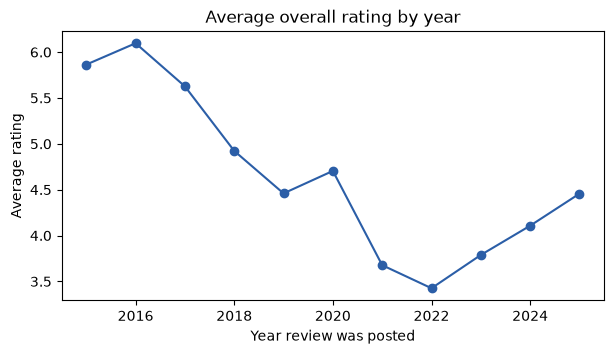

review_date
2015    5.86
2016    6.10
2017    5.63
2018    4.92
2019    4.46
2020    4.70
2021    3.68
2022    3.43
2023    3.79
2024    4.11
2025    4.46
Name: over_all_rating, dtype: float64


In [56]:
year = pd.to_datetime(data.review_date).dt.year
trend = data.groupby(year)[Y_COL].mean()
trend.plot(marker="o", color="#2B5EA7", figsize=(7, 3.5))
plt.title("Average overall rating by year"); plt.xlabel("Year review was posted"); plt.ylabel("Average rating"); plt.show()
print(trend.round(2))

## 13. Limitations, in numbers

In [57]:
out = (y_hat < 1) | (y_hat > 10)
print(f"Out of range: {out.sum():,} of {len(y_hat):,} test predictions ({out.mean():.1%}) fall outside 1–10; lowest {y_hat.min():.2f}")
print(f"Lumpy target: {(y_all == 1).mean():.0%} of reviews are exactly 1")
print(f"Halo effect: {(data[X_COLS].nunique(axis=1) == 1).mean():.0%} of reviewers give all five scores the same value")
print(f"Unexplained: {1 - multi_test['R2']:.0%} of the variation")

Out of range: 1,497 of 9,884 test predictions (15.1%) fall outside 1–10; lowest 0.54
Lumpy target: 30% of reviews are exactly 1
Halo effect: 21% of reviewers give all five scores the same value
Unexplained: 12% of the variation


## 14. Save the trained model and score a new review

In [58]:
import joblib
joblib.dump(multi, "skytrax_rating_model.joblib")

model = joblib.load("skytrax_rating_model.joblib")
new_review = pd.DataFrame([{"value_for_money": 3, "ground_service": 2, "seat_comfort": 4,
                            "cabin_staff_service": 5, "food__beverages": 3}])
print(f"Predicted overall rating: {model.predict(new_review)[0]:.2f}")

Predicted overall rating: 5.36
